In [1]:
import pandas as pd

df = pd.read_csv("../data/clean/upworthy-archive-exploratory-packages-03.12.2020 (1).csv", parse_dates=["created_at", "test_start"])
df.shape               


(22666, 18)

In [2]:
tests = df.groupby("clickability_test_id").agg(
    start = ("test_start", "first"),
    problem = ("problem", "first"),
    n_packages = ("clicks", "size"),   
    
)
tests["problem"].sum()

1050

In [3]:
df.groupby("clickability_test_id")["problem"].nunique().max()

1

In [4]:
flagged = tests[tests["problem"] == 1]["start"]
flagged.min(), flagged.max()

('2013-06-25 03:38:33.509000+00:00', '2014-01-10 20:40:44.428000+00:00')

In [12]:
tests.sort_values("start").query("problem == 0").loc[lambda t: t["start"] < "2013-06-25"].tail(3)


,start,problem,n_packages
clickability_test_id,,,
51c7b78f9e61d4d06c0040db,2013-06-24 03:08:24.803000+00:00,0,4
51c8cc33bd57ec06e200319e,2013-06-24 22:46:35.771000+00:00,0,4
51c8cece234062bbdd003366,2013-06-24 22:57:41.848000+00:00,0,4


In [14]:
tests.sort_values("start").query("problem == 0").loc[lambda t: t["start"] >= "2014-01-11"].head(3)

,start,problem,n_packages
clickability_test_id,,,
52d0ad1b1229172bb2000a47,2014-01-11 02:32:34.622000+00:00,0,2
52d0ce5ddce55b11c50004b9,2014-01-11 04:55:20.697000+00:00,0,4
52d1c8cb011cf1f8ca001a37,2014-01-11 22:43:00.479000+00:00,0,4


In [60]:
clean = df[df["problem"] == 0]
pkg_per_test = clean.groupby("clickability_test_id").size()
print(f"This is how pkg_per_test looks like: {pkg_per_test.head(10)}")
print(f"Total Packages: {pkg_per_test.sum()}", "Total Unique Tests: {len(pkg_per_test}")

This is how pkg_per_test looks like: clickability_test_id
51436061220cb800020001e7    4
51436069220cb800020005ae    5
51436069220cb800020005bd    2
5143606a220cb800020005c6    4
5143606b220cb800020005d7    5
5143606d220cb80002000643    4
5143606e220cb800020006ba    4
51436070220cb80002000748    3
51436071220cb8000200077c    4
51436071220cb80002000788    4
dtype: int64
Total Packages: 18388 Total Unique Tests: {len(pkg_per_test}


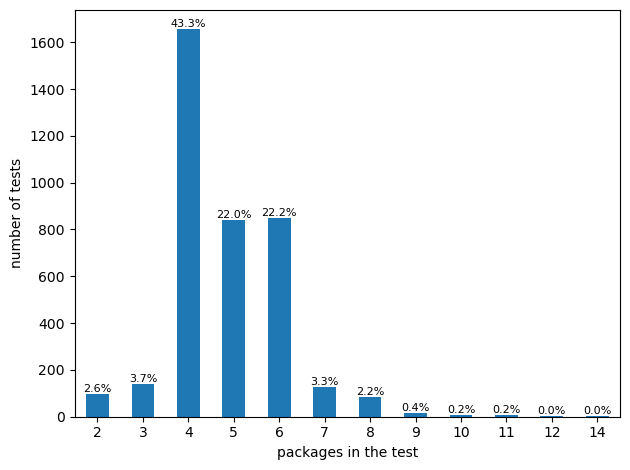

In [80]:
import matplotlib.pyplot as plt

counts = pkg_per_test.value_counts().sort_index()
pct = counts / counts.sum() * 100
bar_plot_counts = counts.plot(kind = "bar")
bar_plot_counts.bar_label(bar_plot_counts.containers[0], labels = [f"{p:.1f}%" for p in pct], fontsize=8)

bar_plot_counts.set_xlabel("packages in the test")
bar_plot_counts.set_ylabel("number of tests")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../reports/figures/packages_per_test.png", dpi=150)
plt.show()

In [64]:
pkg_per_test.describe()

count    3823.000000
mean        4.809835
std         1.240005
min         2.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        14.000000
dtype: float64

In [82]:
clean["impressions"].describe()

count    18388.000000
mean      3490.771101
std       1273.831005
min         13.000000
25%       2768.000000
50%       3118.000000
75%       4031.250000
max      25314.000000
Name: impressions, dtype: float64

In [94]:
clean = clean.copy()
clean["ctr"] = clean["clicks"] / clean["impressions"]
print(clean["ctr"].describe())
print(clean["test_week"].head())

count    18388.000000
mean         0.013620
std          0.009928
min          0.000000
25%          0.006724
50%          0.011131
75%          0.017527
max          0.122842
Name: ctr, dtype: float64
0    201446
1    201446
2    201446
3    201446
4    201446
Name: test_week, dtype: int64


In [92]:
n_small = (clean["impressions"] < 1000).sum()
print(f"packages under 1,000 impressions: {n_small} ({n_small / len(clean):.2%})")

packages under 1,000 impressions: 13 (0.07%)


### Zero click packages

In [101]:
print((clean["clicks"] == 0).sum())

10


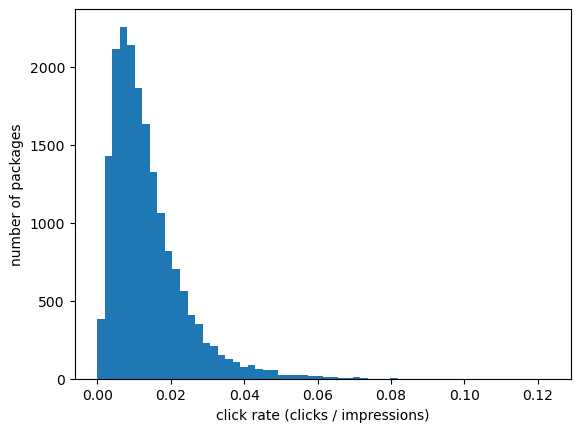

In [103]:
ctr_plot = clean["ctr"].plot(kind = "hist", bins = 60)
ctr_plot.set_xlabel("click rate (clicks / impressions)")
ctr_plot.set_ylabel("number of packages")
plt.show()

93
count    93.000000
mean      0.014824
std       0.005271
min       0.006444
25%       0.011172
50%       0.013251
75%       0.017647
max       0.032184
Name: ctr, dtype: float64


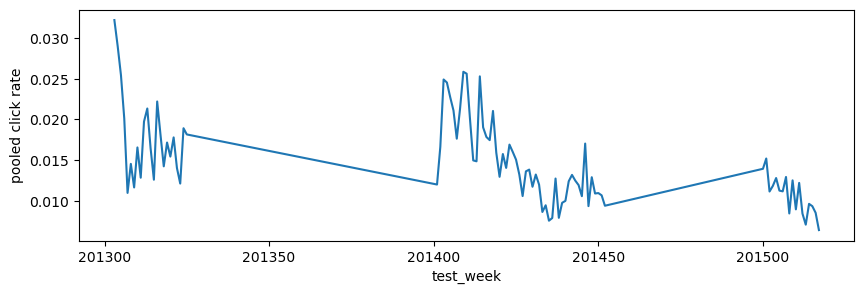

In [107]:
# clt per week
weekly = clean.groupby("test_week").agg(
    clicks = ("clicks", "sum"),
    impressions = ("impressions", "sum"),
    n_packages = ("clicks", "size"),
)

weekly["ctr"] = weekly["clicks"] / weekly["impressions"]
print(len(weekly)) #number of weeks
print(weekly["ctr"].describe())
weekly["ctr"].plot(figsize=(10,3))
plt.ylabel("pooled click rate")
plt.show()